# Initial Modeling: `OD_PAX` Demand

This notebook is a simple, teaching-focused first pass at forecasting American Airlines passenger demand. The target is **`OD_PAX`**, which represents passengers on an origin-destination route for a departure month.

The source file is monthly, not daily. Therefore, the requested next-day workflow is shown as a **next-period workflow**: one prediction is made for the next available month, then that prediction is used to make the following prediction. A two-year horizon is consequently 24 monthly periods.

We will compare simple ARIMA/SARIMAX, Random Forest, XGBoost, LSTM, and a simple average ensemble. These are introductory baselines, not production-ready forecasts.

## 1. Imports and reproducibility

The optional XGBoost and TensorFlow imports are handled explicitly. If either package is not installed, the notebook still runs the rest of the analysis and explains how to enable that model.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.preprocessing import MinMaxScaler

warnings.filterwarnings("ignore")
np.random.seed(42)
plt.style.use("seaborn-v0_8-whitegrid")

try:
    from statsmodels.tsa.arima.model import ARIMA
    from statsmodels.tsa.statespace.sarimax import SARIMAX
    statsmodels_available = True
except ImportError:
    statsmodels_available = False
    print("statsmodels is not installed; ARIMA/SARIMAX cells will be skipped.")

try:
    from xgboost import XGBRegressor
    xgboost_available = True
except ImportError:
    xgboost_available = False
    print("xgboost is not installed; the XGBoost cell will be skipped.")

try:
    import tensorflow as tf
    from tensorflow.keras import Sequential
    from tensorflow.keras.layers import Dense, LSTM
    tensorflow_available = True
    tf.random.set_seed(42)
except ImportError:
    tensorflow_available = False
    print("tensorflow is not installed; the LSTM cell will be skipped.")

statsmodels is not installed; ARIMA/SARIMAX cells will be skipped.
tensorflow is not installed; the LSTM cell will be skipped.


## 2. Load and prepare the data

The data contains one row per origin, destination, and departure month. To keep this first notebook surface-level, we aggregate all routes into one monthly demand series. We use only `OD_PAX` as the prediction target and do not use same-month revenue because it would not be known when forecasting future demand.

In [2]:
candidate_paths = [
    Path.cwd() / "data" / "AA_PAX_FORECASTING.csv",
    Path.cwd().parent / "data" / "AA_PAX_FORECASTING.csv",
]
data_path = next((path for path in candidate_paths if path.exists()), None)
if data_path is None:
    raise FileNotFoundError(
        "Could not find data/AA_PAX_FORECASTING.csv. Run this notebook from the repository "
        "root or from pm-modeling/."
    )

raw = pd.read_csv(data_path)
raw["DATE"] = pd.to_datetime(
    raw["DEP_YEAR"].astype(str) + "-" + raw["DEP_MONTH"].astype(str) + "-01"
)
raw["OD_PAX"] = pd.to_numeric(raw["OD_PAX"], errors="coerce")

monthly = (
    raw.dropna(subset=["DATE", "OD_PAX"])
    .groupby("DATE", as_index=True)["OD_PAX"]
    .sum()
    .sort_index()
    .asfreq("MS")
)
monthly = monthly.interpolate(limit_direction="both")
monthly.name = "OD_PAX"

print(f"Loaded: {data_path}")
print(f"Raw rows: {len(raw):,}")
print(f"Monthly observations: {len(monthly):,}")
monthly.head()

Loaded: C:\Users\hrudi\Documents\ADSC\fall2026\projects\fall2026-american-airlines\data\AA_PAX_FORECASTING.csv
Raw rows: 1,533,522
Monthly observations: 91


DATE
2019-01-01    45851853.05
2019-02-01    43680104.30
2019-03-01    54872107.41
2019-04-01    53122925.67
2019-05-01    56138934.70
Freq: MS, Name: OD_PAX, dtype: float64

## 3. Basic EDA

These checks answer simple questions: how large is the dataset, are values missing, what is the range of demand, and does demand appear to trend or repeat by month?

In [3]:
display(raw[["DEP_MONTH", "DEP_YEAR", "OD_PAX"]].describe())
print("Missing values in the raw target:", raw["OD_PAX"].isna().sum())
print("Missing values after monthly preparation:", monthly.isna().sum())
display(monthly.describe().to_frame("OD_PAX"))

,DEP_MONTH,DEP_YEAR,OD_PAX
count,1.533522e+06,1.533522e+06,1.533522e+06
mean,6.311087e+00,2.022340e+03,2.765159e+03
std,3.440110e+00,2.197267e+00,6.667135e+03
min,1.000000e+00,2.019000e+03,1.300000e-01
25%,3.000000e+00,2.020000e+03,1.292600e+02
50%,6.000000e+00,2.022000e+03,5.026550e+02
75%,9.000000e+00,2.024000e+03,2.104030e+03
max,1.200000e+01,2.026000e+03,1.401943e+05


Missing values in the raw target: 0
Missing values after monthly preparation: 0


,OD_PAX
count,9.100000e+01
mean,4.659816e+07
std,1.413752e+07
min,1.966141e+06
25%,4.470703e+07
50%,5.086421e+07
75%,5.623199e+07
max,6.266779e+07


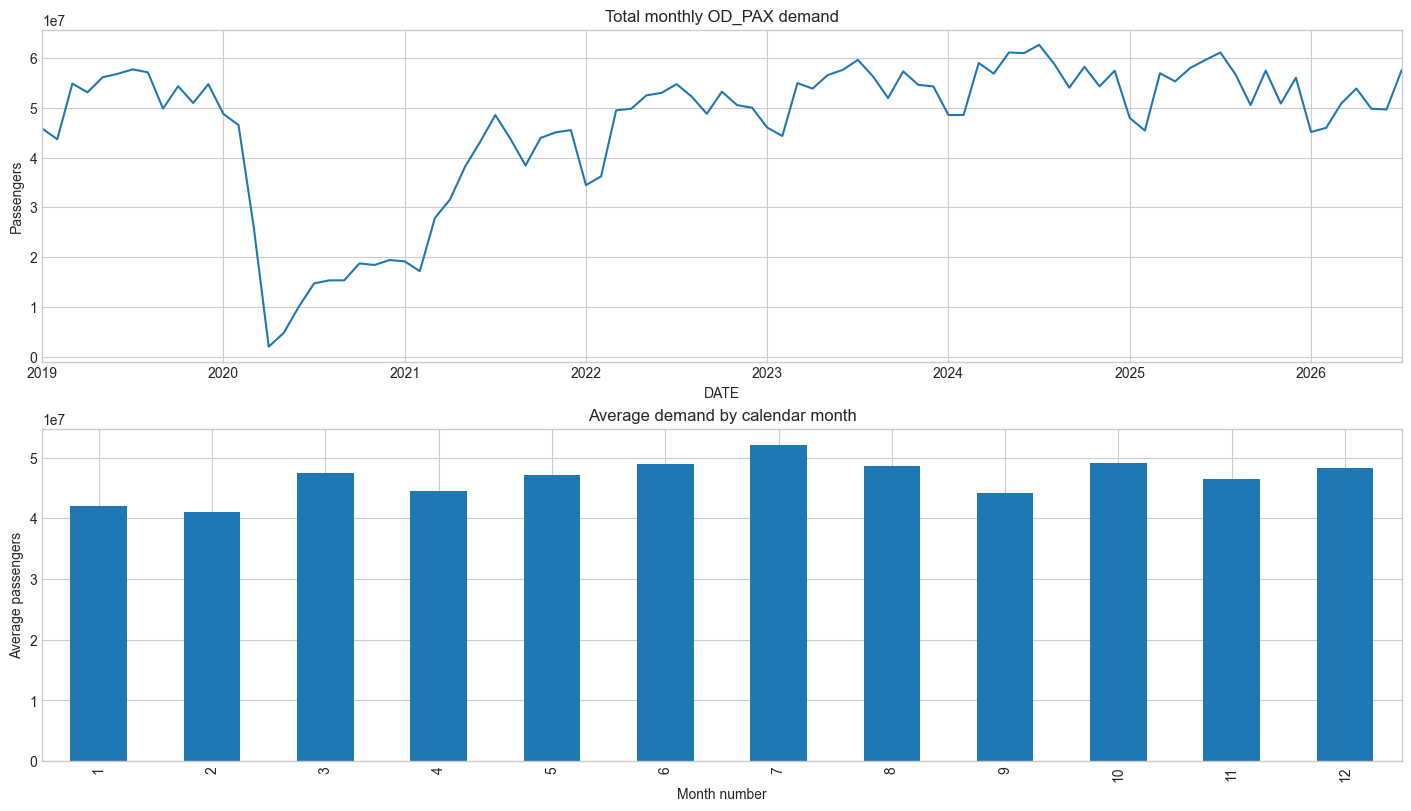

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8), constrained_layout=True)
monthly.plot(ax=axes[0], title="Total monthly OD_PAX demand")
axes[0].set_ylabel("Passengers")
monthly.groupby(monthly.index.month).mean().plot(kind="bar", ax=axes[1], title="Average demand by calendar month")
axes[1].set_xlabel("Month number")
axes[1].set_ylabel("Average passengers")
plt.show()

# This is only a visual check. The seasonal pattern is one reason to try a seasonal model such as SARIMAX and a lag-12 feature for the tree models.

## 4. Time-based train/test split

Time series must be split in chronological order. We reserve the most recent **24 months** as the test set. No test values are used to fit the models. This is a more realistic setup than randomly mixing past and future observations.

Training period: 2019-01-01 through 2024-07-01
Test period:     2024-08-01 through 2026-07-01


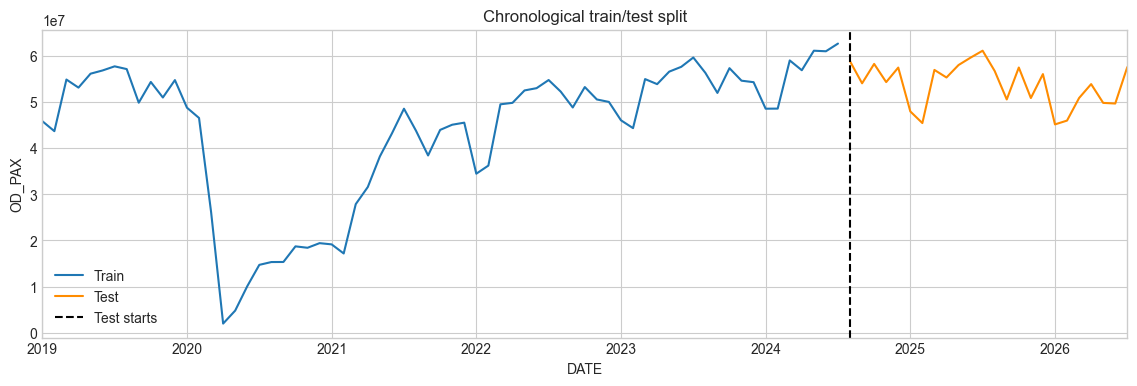

In [5]:
TEST_PERIODS = 24
if len(monthly) <= TEST_PERIODS + 24:
    raise ValueError("The series needs more than 48 monthly observations for this demonstration.")

train = monthly.iloc[:-TEST_PERIODS].copy()
test = monthly.iloc[-TEST_PERIODS:].copy()

print(f"Training period: {train.index.min().date()} through {train.index.max().date()}")
print(f"Test period:     {test.index.min().date()} through {test.index.max().date()}")
assert len(test) == TEST_PERIODS

fig, ax = plt.subplots(figsize=(14, 4))
train.plot(ax=ax, label="Train")
test.plot(ax=ax, label="Test", color="darkorange")
ax.axvline(test.index[0], color="black", linestyle="--", label="Test starts")
ax.set_title("Chronological train/test split")
ax.set_ylabel("OD_PAX")
ax.legend()
plt.show()

## 5. Helper functions and simple baseline

We will use MAE and RMSE. MAE is the average absolute error in passengers. RMSE penalizes larger mistakes more strongly. A seasonal-naive forecast is a useful reference: it predicts this month using the value from 12 months earlier.

In [6]:
def metrics(actual, predicted):
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
    }

def seasonal_naive(history, periods, season_length=12):
    values = list(history.astype(float))
    predictions = []
    for _ in range(periods):
        prediction = values[-season_length] if len(values) >= season_length else values[-1]
        predictions.append(prediction)
        values.append(prediction)
    return np.array(predictions)

seasonal_pred = seasonal_naive(train, len(test))
metrics_table = pd.DataFrame([metrics(test, seasonal_pred)], index=["Seasonal naive"])
metrics_table

,MAE,RMSE
Seasonal naive,3.113174e+06,4.319585e+06


## 6. ARIMA and SARIMAX

ARIMA models use past values and past errors. SARIMAX adds seasonal structure. These settings are deliberately small and are not tuned. The model forecasts the entire 24-month test horizon from the training data, which is the common recursive multi-step behavior of these models.

In [7]:
model_predictions = {"Seasonal naive": seasonal_pred}

if statsmodels_available:
    arima_fit = ARIMA(train, order=(1, 1, 1)).fit()
    model_predictions["ARIMA"] = arima_fit.forecast(steps=len(test)).to_numpy()

    sarimax_fit = SARIMAX(
        train,
        order=(1, 1, 1),
        seasonal_order=(1, 0, 1, 12),
        enforce_stationarity=False,
        enforce_invertibility=False,
    ).fit(disp=False)
    model_predictions["SARIMAX"] = sarimax_fit.forecast(steps=len(test)).to_numpy()
else:
    print("Skipping ARIMA and SARIMAX because statsmodels is unavailable.")

pd.DataFrame({name: metrics(test, prediction) for name, prediction in model_predictions.items()}).T

Skipping ARIMA and SARIMAX because statsmodels is unavailable.


,MAE,RMSE
Seasonal naive,3.113174e+06,4.319585e+06


## 7. Lag features for Random Forest and XGBoost

Tree models do not automatically understand time order. We give them a few simple features: the previous month, the value from the same month last year, a short rolling average, and calendar-month sine/cosine values. During forecasting, predictions are fed back into the feature history so that future unknown values are not accidentally used.

In [8]:
def make_features(values, date):
    values = list(values)
    lag_1 = values[-1]
    lag_12 = values[-12] if len(values) >= 12 else values[-1]
    rolling_3 = float(np.mean(values[-3:]))
    month = date.month
    return [
        lag_1,
        lag_12,
        rolling_3,
        np.sin(2 * np.pi * month / 12),
        np.cos(2 * np.pi * month / 12),
    ]

feature_rows = []
target_rows = []
for i in range(12, len(train)):
    feature_rows.append(make_features(train.iloc[:i].to_numpy(), train.index[i]))
    target_rows.append(train.iloc[i])
X_train = np.asarray(feature_rows)
y_train = np.asarray(target_rows)

def recursive_tree_forecast(model, history, future_index):
    values = list(history.astype(float))
    predictions = []
    for date in future_index:
        x_next = np.asarray(make_features(values, date)).reshape(1, -1)
        prediction = float(model.predict(x_next)[0])
        prediction = max(0.0, prediction)
        predictions.append(prediction)
        values.append(prediction)
    return np.asarray(predictions)

rf = RandomForestRegressor(n_estimators=100, random_state=42, min_samples_leaf=2, n_jobs=-1)
rf.fit(X_train, y_train)
model_predictions["Random Forest"] = recursive_tree_forecast(rf, train, test.index)

if xgboost_available:
    xgb = XGBRegressor(
        n_estimators=100,
        max_depth=3,
        learning_rate=0.05,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=2,
    )
    xgb.fit(X_train, y_train, verbose=False)
    model_predictions["XGBoost"] = recursive_tree_forecast(xgb, train, test.index)
else:
    print("Skipping XGBoost because xgboost is unavailable.")

## 8. Small LSTM baseline

An LSTM is a neural network designed for sequences. This example uses a small 12-month input window and one hidden LSTM layer. It is intentionally small so the notebook stays understandable and runs quickly. Neural networks are sensitive to scale, so the target is scaled before training and transformed back afterward.

In [9]:
def lstm_forecast(history, future_index, window=12):
    values = history.to_numpy(dtype=float).reshape(-1, 1)
    scaler = MinMaxScaler()
    scaled = scaler.fit_transform(values)
    X, y = [], []
    for i in range(window, len(scaled)):
        X.append(scaled[i - window:i, 0])
        y.append(scaled[i, 0])
    X = np.asarray(X).reshape(-1, window, 1)
    y = np.asarray(y)

    model = Sequential([
        LSTM(16, input_shape=(window, 1)),
        Dense(1),
    ])
    model.compile(optimizer="adam", loss="mse")
    model.fit(X, y, epochs=20, batch_size=8, verbose=0)

    history_scaled = list(scaled[:, 0])
    predictions = []
    for _ in future_index:
        x_next = np.asarray(history_scaled[-window:]).reshape(1, window, 1)
        prediction_scaled = float(model.predict(x_next, verbose=0)[0, 0])
        prediction = float(scaler.inverse_transform([[prediction_scaled]])[0, 0])
        prediction = max(0.0, prediction)
        predictions.append(prediction)
        history_scaled.append(prediction_scaled)
    return np.asarray(predictions)

if tensorflow_available:
    model_predictions["LSTM"] = lstm_forecast(train, test.index)
else:
    print("Skipping LSTM because tensorflow is unavailable. Install tensorflow to run it.")

Skipping LSTM because tensorflow is unavailable. Install tensorflow to run it.


## 9. Compare one-step-ahead recursive forecasts

For this notebook, “predict the next day each day” means: predict the next available monthly period, append that prediction to the history, and repeat until the 24-month test horizon is complete. This intentionally tests how errors can accumulate in a recursive forecast.

,MAE,RMSE
Seasonal naive,3113174.10,4319584.87
XGBoost,4012361.82,5256153.92
Random Forest,5680803.49,6761747.84


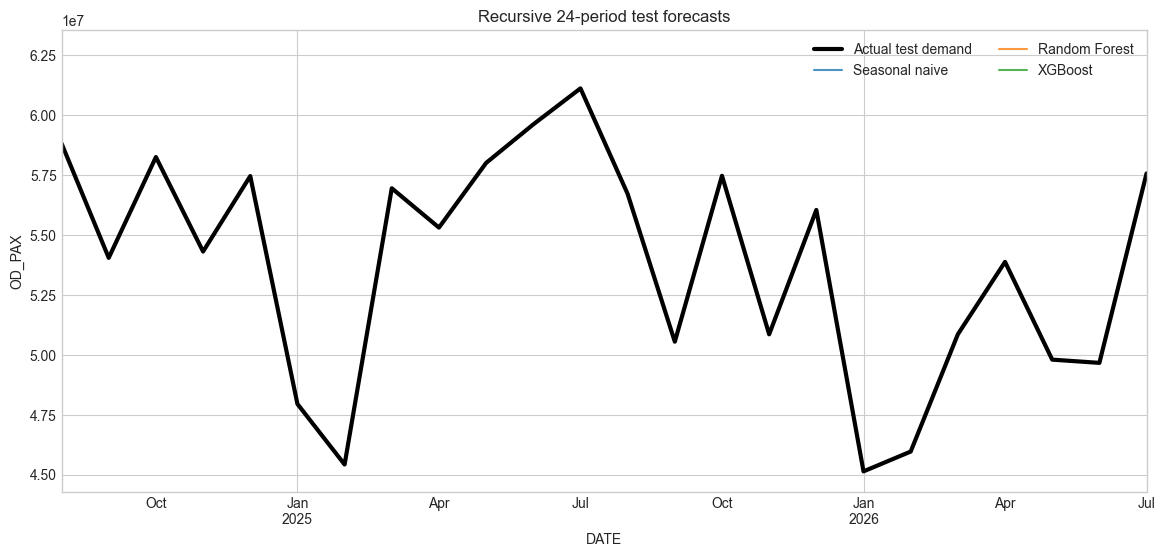

In [ ]:
metrics_table = pd.DataFrame(
        {name: metrics(test, prediction) for name, prediction in model_predictions.items()}
    ).T.sort_values("RMSE")
display(metrics_table.round(2))

fig, ax = plt.subplots(figsize=(14, 6))
test.plot(ax=ax, color="black", linewidth=3, label="Actual test demand")
for name, prediction in model_predictions.items():
        ax.plot(test.index, prediction, label=name, alpha=0.8)
ax.set_title("Recursive 24-period test forecasts")
ax.set_ylabel("OD_PAX")
ax.legend(ncol=2)
plt.show()

## 10. Simple ensemble

An ensemble can reduce dependence on one model. Here we use the simplest possible ensemble: an equal-weight average of every available model's recursive forecast. More advanced ensembles would learn weights from validation data, but that is outside this introductory notebook.

In [11]:
ensemble_members = list(model_predictions)
ensemble_prediction = np.mean(np.vstack([model_predictions[name] for name in ensemble_members]), axis=0)
model_predictions["Simple ensemble"] = ensemble_prediction
metrics_table = pd.DataFrame(
        {name: metrics(test, prediction) for name, prediction in model_predictions.items()}
    ).T.sort_values("RMSE")
display(metrics_table.round(2))

,MAE,RMSE
Seasonal naive,3113174.10,4319584.87
Simple ensemble,4013350.49,5184236.17
XGBoost,4012361.82,5256153.92
Random Forest,5680803.49,6761747.84


## 11. Forecast the next two years from the end of the data

The test set measures performance on known historical data. This section then refits the non-neural models on **all available months** and forecasts the next 24 months beyond the dataset. This is a future scenario, so there are no actual values to score yet.

For the tree models and LSTM, the same recursive process is used. ARIMA and SARIMAX produce a 24-step forecast directly from their fitted time-series model.

In [12]:
future_index = pd.date_range(
    monthly.index.max() + pd.offsets.MonthBegin(1), periods=TEST_PERIODS, freq="MS"
)
future_predictions = {}
future_predictions["Seasonal naive"] = seasonal_naive(monthly, TEST_PERIODS)

if statsmodels_available:
    full_arima = ARIMA(monthly, order=(1, 1, 1)).fit()
    future_predictions["ARIMA"] = full_arima.forecast(steps=TEST_PERIODS).to_numpy()
    full_sarimax = SARIMAX(
        monthly,
        order=(1, 1, 1),
        seasonal_order=(1, 0, 1, 12),
        enforce_stationarity=False,
        enforce_invertibility=False,
    ).fit(disp=False)
    future_predictions["SARIMAX"] = full_sarimax.forecast(steps=TEST_PERIODS).to_numpy()

full_feature_rows = []
full_target_rows = []
for i in range(12, len(monthly)):
    full_feature_rows.append(make_features(monthly.iloc[:i].to_numpy(), monthly.index[i]))
    full_target_rows.append(monthly.iloc[i])
full_X = np.asarray(full_feature_rows)
full_y = np.asarray(full_target_rows)

full_rf = RandomForestRegressor(n_estimators=100, random_state=42, min_samples_leaf=2, n_jobs=-1)
full_rf.fit(full_X, full_y)
future_predictions["Random Forest"] = recursive_tree_forecast(full_rf, monthly, future_index)

if xgboost_available:
    full_xgb = XGBRegressor(
        n_estimators=100,
        max_depth=3,
        learning_rate=0.05,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=2,
    )
    full_xgb.fit(full_X, full_y, verbose=False)
    future_predictions["XGBoost"] = recursive_tree_forecast(full_xgb, monthly, future_index)

if tensorflow_available:
    future_predictions["LSTM"] = lstm_forecast(monthly, future_index)

future_predictions["Simple ensemble"] = np.mean(
    np.vstack(list(future_predictions.values())), axis=0
)
future_forecast = pd.DataFrame(future_predictions, index=future_index)
future_forecast.head()

,Seasonal naive,Random Forest,XGBoost,Simple ensemble
2026-08-01,56721019.37,5.675354e+07,57897000.0,5.712385e+07
2026-09-01,50557191.40,5.391315e+07,53561840.0,5.267739e+07
2026-10-01,57478420.11,5.730270e+07,57103592.0,5.729490e+07
2026-11-01,50864205.84,5.455461e+07,53850832.0,5.308988e+07
2026-12-01,56053345.45,5.668356e+07,56693192.0,5.647670e+07


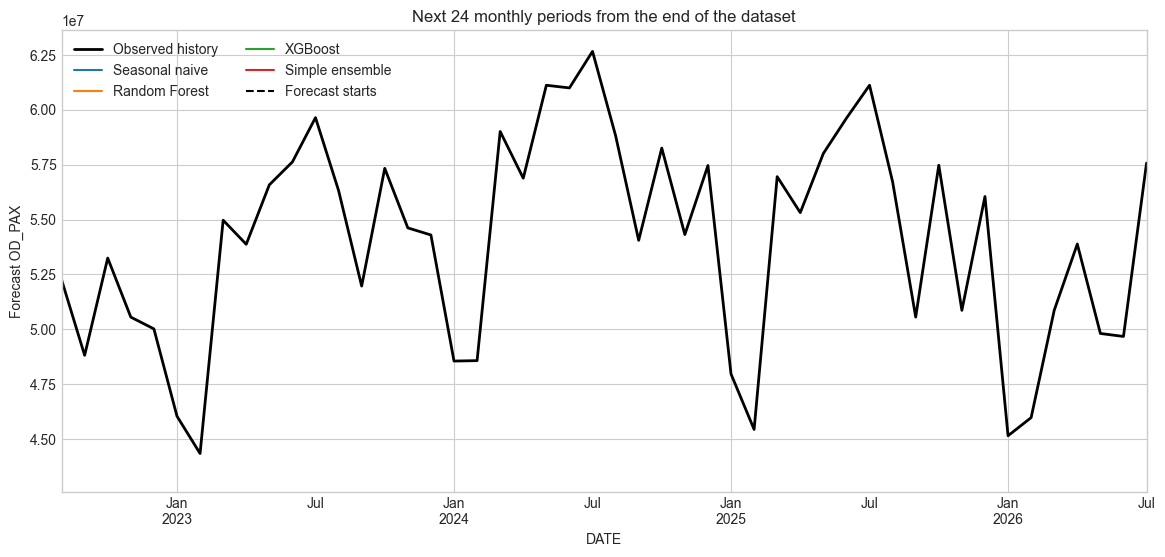

,Seasonal naive,Random Forest,XGBoost,Simple ensemble
2026-08-01,56721019.4,56753540.9,57897000.0,57123853.4
2026-09-01,50557191.4,53913151.3,53561840.0,52677394.2
2026-10-01,57478420.1,57302699.4,57103592.0,57294903.8
2026-11-01,50864205.8,54554610.7,53850832.0,53089882.8
2026-12-01,56053345.4,56683561.7,56693192.0,56476699.7
2027-01-01,45147304.8,48199785.3,48306096.0,47217728.7
2027-02-01,45974031.5,45540291.4,45599780.0,45704700.9
2027-03-01,50866217.1,47025178.1,45448440.0,47779945.1
2027-04-01,53886166.1,43522966.1,47533392.0,48314174.7
2027-05-01,49808898.0,48286730.4,43639772.0,47245133.5


In [13]:
fig, ax = plt.subplots(figsize=(14, 6))
monthly.iloc[-48:].plot(ax=ax, label="Observed history", color="black", linewidth=2)
for name in future_forecast.columns:
        ax.plot(future_forecast.index, future_forecast[name], label=name)
ax.axvline(monthly.index.max(), color="black", linestyle="--", label="Forecast starts")
ax.set_title("Next 24 monthly periods from the end of the dataset")
ax.set_ylabel("Forecast OD_PAX")
ax.legend(ncol=2)
plt.show()

display(future_forecast.round(1))

## 12. Takeaways and limitations

- `OD_PAX` was aggregated across routes into one monthly demand series.
- The latest 24 months were held out as a chronological test set.
- The recursive workflow repeatedly predicts one future period and feeds that prediction back into the next step.
- The direct future workflow forecasts 24 periods beyond the latest observed month.
- The ensemble is a simple average, not a tuned or optimized combination.
- Because the input data is monthly, this notebook does not create daily forecasts. A true daily model would require daily demand observations or an explicit disaggregation plan.
- Route-level forecasts, external drivers, uncertainty intervals, hyperparameter tuning, and production monitoring are intentionally left for future work.